# Setup

## Load packages

In [1]:
library(tidyverse)  # Data wrangling packages.

library(dplyr)
library(broom)

install.packages("pROC")
library(pROC)

install.packages("caret")
library(caret)

install.packages("glmnet")
library(glmnet)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var


Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Loading required package: lattice


Attaching package: ‘caret’


The following object is masked from ‘package:purrr’:

    lift


Updating HTML index of packages in 

## Load and merge data

In [2]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"


demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file) 

all_data <- merge(
  demo,
  ses_data,
  by = "person_id"
)

name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)

merged_data<-merge(all_data, case_control, on="person_id", how="inner")

Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Format data

In [3]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

merged_data$age2 <- merged_data$age^2

domains <-c('individual_poverty', 'education',
         'fraction_assisted_income', 'fraction_no_high_school_education', 'lower_median_income', 
         'fraction_no_health_insurance', 'fraction_poverty', 'fraction_vacant_housing', 'deprivation_index'
)

#Hard code to match disease names in case_control dataframe 
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")

# Elastic Net Function

In [4]:
run_elastic_net <- function(diseases, selection_terms, merged_data) {

  ####---------------------------------------------------------------
  #### 1. Containers
  ####---------------------------------------------------------------

  individual_scores <- list()
  weights_list      <- list()

  set.seed(123)

  ####---------------------------------------------------------------
  #### 2. Loop over diseases
  ####---------------------------------------------------------------

  for (disease in diseases) {

    df <- merged_data %>%
      select(person_id, all_of(disease), all_of(selection_terms)) %>%
      drop_na()

    X <- as.matrix(df %>% select(all_of(selection_terms)))
    y <- as.numeric(df[[disease]])

    penalty_factors <- rep(1, ncol(X))


    ####-----------------------------------------------------------
    #### 3. Full-data refit (FINAL MODEL FOR WEIGHTS)
    ####-----------------------------------------------------------

    scale_min_full <- apply(X, 2, min)
    scale_max_full <- apply(X, 2, max)
    scale_rng_full <- scale_max_full - scale_min_full
    scale_rng_full[scale_rng_full == 0] <- 1

    X_scaled <- sweep(sweep(X, 2, scale_min_full, "-"), 2, scale_rng_full, "/")

    cv_full <- cv.glmnet(
      X_scaled, y,
      alpha = 0.5,
      family = "binomial",
      penalty.factor = penalty_factors
    )

    lambda_final <- cv_full$lambda.min

    final_fit <- glmnet(
      X_scaled, y,
      alpha = 0.5,
      lambda = lambda_final,
      family = "binomial",
      penalty.factor = penalty_factors
    )

    coef_final <- as.vector(coef(final_fit))
    names(coef_final) <- rownames(coef(final_fit))

    ####-----------------------------------------------------------
    #### 4. Store weights + scaling metadata
    ####-----------------------------------------------------------

    weights_list[[disease]] <- tibble(
      Disease     = disease,
      Predictor   = names(coef_final),
      weight      = coef_final,
      scale_min   = c(0, scale_min_full),
      scale_max   = c(1, scale_max_full),
      scale_range = c(1, scale_rng_full)
    )

    ####-----------------------------------------------------------
    #### 5. Compute individual PsRS (reference scores)
    ####-----------------------------------------------------------

    Xb <- X_scaled %*% coef_final[-1] + coef_final[1]

    individual_scores[[disease]] <- tibble(
      person_id = df$person_id,
      prediction = as.numeric(Xb)
    )

    message("Completed Elastic Net for: ", disease)
  }

  ####---------------------------------------------------------------
  #### 6. Final weights tables
  ####---------------------------------------------------------------

  scales <- bind_rows(weights_list) |> select(-c(weight))
  weights_long <- bind_rows(weights_list)

  weights_wide <- weights_long %>%
    select(Disease, Predictor, weight) %>%
    pivot_wider(names_from = Disease, values_from = weight)

  ####---------------------------------------------------------------
  #### 7. Return
  ####---------------------------------------------------------------

  list(
    individual_scores = individual_scores,
    scales            = scales,
    weights_wide      = weights_wide
  )
}


# Run ENs

In [5]:
results_all <- run_elastic_net(diseases, domains, merged_data)


Completed Elastic Net for: Asthma

Completed Elastic Net for: Afib

Completed Elastic Net for: BreastC

Completed Elastic Net for: CKD

Completed Elastic Net for: CHD

Completed Elastic Net for: ProstateC

Completed Elastic Net for: t2d

Completed Elastic Net for: t1d



In [6]:
selection_terms_no_income<- setdiff(domains, "indiviudal_poverty")      
      

results_no_income <- run_elastic_net(diseases, selection_terms_no_income, merged_data)


Completed Elastic Net for: Asthma

Completed Elastic Net for: Afib

Completed Elastic Net for: BreastC

Completed Elastic Net for: CKD

Completed Elastic Net for: CHD

Completed Elastic Net for: ProstateC

Completed Elastic Net for: t2d

Completed Elastic Net for: t1d



# Save files

## Weights Files

In [7]:
write_excel_csv(results_all[[3]], file.path(output_dir, "PsRS_weights_file.csv"))
write_excel_csv(results_no_income[[3]], file.path(output_dir, "PsRS_weights_file_no_income.csv"))

## Scaling Files

In [8]:
write_excel_csv(results_all[[2]], file.path(output_dir, "PsRS_scaling_file.csv"))
write_excel_csv(results_no_income[[2]], file.path(output_dir, "PsRS_scaling_file_no_income.csv"))

# Calculate PsRS using AoU weights

### Code for collaborators to calculate PsRS using AoU weights in external datasets

In [9]:
name_of_file_in_bucket <- 'PsRS_weights_file_no_income.csv'
PsRS_weights_no_income <- read_csv(paste0(current_directory, "/data/", name_of_file_in_bucket))

name_of_file_in_bucket <- 'PsRS_weights_file.csv'
PsRS_weights <- read_csv(paste0(current_directory, "/data/", name_of_file_in_bucket))

name_of_file_in_bucket <- 'PsRS_scaling_file_no_income.csv'
PsRS_scaling_no_income <- read_csv(paste0(current_directory, "/data/", name_of_file_in_bucket))

name_of_file_in_bucket <- 'PsRS_scaling_file.csv'
PsRS_scaling <- read_csv(paste0(current_directory, "/data/", name_of_file_in_bucket))


Rows: 10 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): Predictor
dbl (8): Asthma, Afib, BreastC, CKD, CHD, ProstateC, t2d, t1d

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 10 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): Predictor
dbl (8): Asthma, Afib, BreastC, CKD, CHD, ProstateC, t2d, t1d

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 80 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): Disease, Predictor
dbl (3): scale_min, scale_max, scale_range

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `s

## Functions

In [17]:
compute_PsRS <- function(domains, PsRS_weights, PsRS_scaling) {
  # ---- 0. Add intercept column ----
  all_data_with_intercept <- all_data %>%
    mutate(`(Intercept)` = 1)
    
  # ---- 1. Pivot all_data to long for predictors only ----
  long_data <- all_data_with_intercept %>%
    pivot_longer(
      cols = c(all_of(domains), `(Intercept)`),
      names_to = "Predictor",
      values_to = "value")

  # ---- 2. Pivot weights to long ----
  weights_long <- PsRS_weights %>%
    pivot_longer(
      cols = all_of(diseases),
      names_to = "Disease",
      values_to = "coef")
  
  # ---- 3. Expand for each disease ----
  # Create all combinations of person_id, Predictor, and disease
  long_data_expanded <- expand_grid(
    person_id= unique(all_data$person_id),
    Predictor = unique(long_data$Predictor),
    Disease = diseases
  ) %>%
    left_join(long_data, by = c("person_id", "Predictor"))
  
  # ---- 4. Join weights and scaling ----
  long_data_scaled <- long_data_expanded %>%
    left_join(weights_long, by = c("Predictor", "Disease")) %>%
    left_join(PsRS_scaling, by = c("Predictor", "Disease")) %>%
    mutate(
      value_scaled = if_else(
        Predictor == "(Intercept)",
       value,
        (value - scale_min) / (scale_max - scale_min)
      ),
      score_part = value_scaled * coef
    )

  # ---- 5. Aggregate to compute PsRS ----
  score_wide <- long_data_scaled %>%
    group_by(person_id, Disease) %>%
    summarize(score = sum(score_part, na.rm = TRUE), .groups = "drop") %>%
    pivot_wider(
      names_from = Disease,
      values_from = score,
      values_fill = 0
    ) %>%
    rename_with(~ paste0(., "_PsRS"), -person_id)
  
  # ---- 6. Apply inverse normalization
  results_zscore <- score_wide %>%
    mutate(across(
      .cols = -person_id,
      .fns = ~ scale(.x)
    )) %>%
  mutate(
    across(ends_with("_PsRS"), ~ as.numeric(.))
  )

  
  return(results_zscore)
}


plot_PsRS <- function(score_wide) {
  
  # Pivot to long format
  scores_long <- score_wide %>%
    pivot_longer(
      cols = ends_with("_PsRS"),
      names_to = "disease",
      values_to = "score"
    )

  # Plot facet-wrapped histograms
  plot<-ggplot(scores_long, aes(x = score)) +
    geom_histogram(bins = 40, fill = "skyblue", color = "white") +
    facet_wrap(~ disease, scales = "free") +
    theme_minimal() +
    labs(
      title = "Distribution of PsRS",
      x = "Score",
      y = "Count"
    ) +
    theme(
      plot.title = element_text(size = 16, face = "bold"),
      strip.text = element_text(size = 12)
    )
  return(plot)
}


## PsRS with income

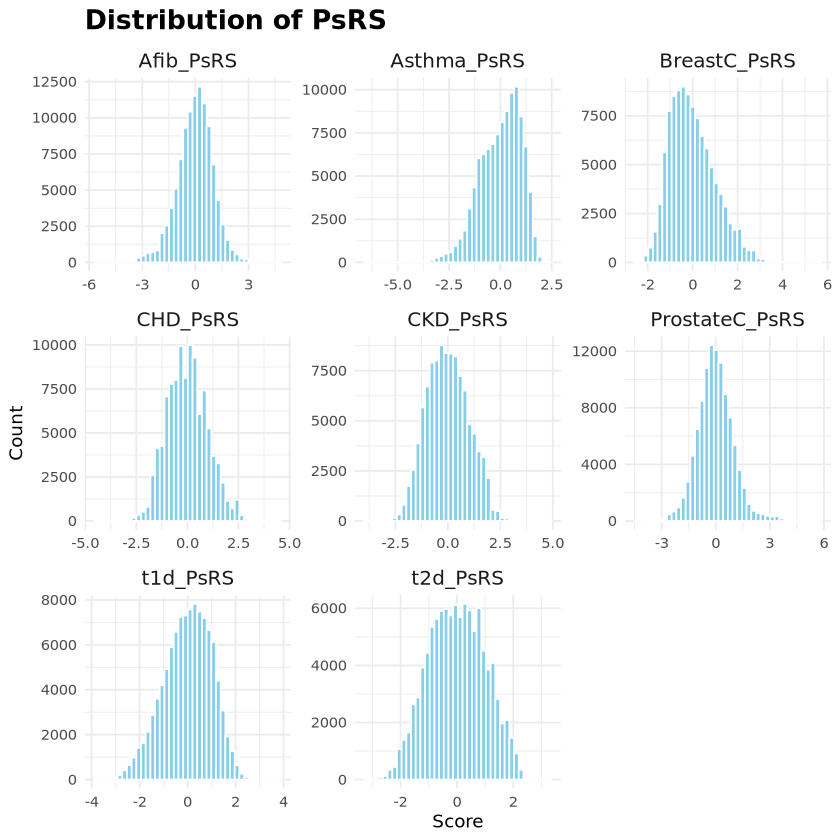

In [18]:
results <- compute_PsRS(domains, PsRS_weights, PsRS_scaling)
plot_PsRS(results)
write_excel_csv(results, file.path(output_dir, "individual_PsRS.csv"))

## PsRS without income

[1] "education"                         "fraction_assisted_income"         
[3] "fraction_no_high_school_education" "lower_median_income"              
[5] "fraction_no_health_insurance"      "fraction_poverty"                 
[7] "fraction_vacant_housing"           "deprivation_index"

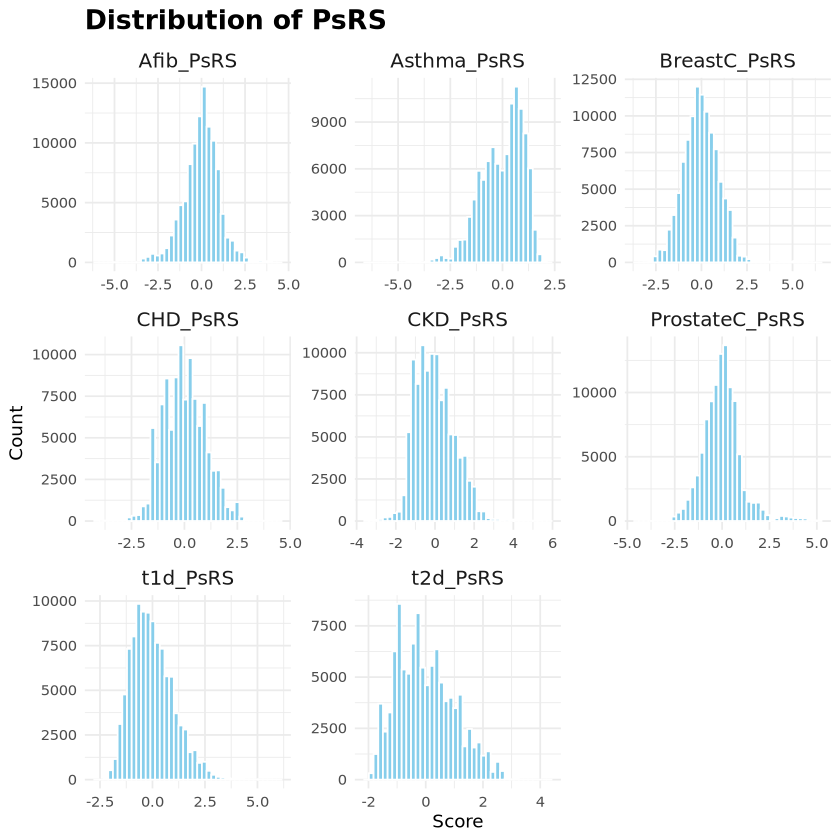

In [20]:
selection_terms_no_income<- setdiff(domains, "individual_poverty")      
selection_terms_no_income
results_no_income <- compute_PsRS(selection_terms_no_income, PsRS_weights_no_income, PsRS_scaling_no_income)
plot_PsRS(results_no_income)
write_excel_csv(results, file.path(output_dir, "individual_PsRS_no_income.csv"))